In [16]:
import os, json
import numpy as np
import pandas as pd
import joblib
from PIL import Image, ImageOps
from skimage.feature import hog
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score


warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
%pip install -q huggingface_hub

from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="keycxl/DENTEX",
    repo_type="dataset",
    local_dir="dentex_data",
    allow_patterns=["DENTEX/training_data.zip"]
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

'/content/dentex_data'

In [3]:
import zipfile

ZIP_PATH    = "dentex_data/DENTEX/training_data.zip"
EXTRACT_DIR = "dentex_train"


if not (os.path.isdir(EXTRACT_DIR) and os.listdir(EXTRACT_DIR)):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

print("Top level of the unzipped data:", os.listdir(EXTRACT_DIR))


def find_folder(root, wanted):
    for folder, subfolders, _ in os.walk(root):
        if "__MACOSX" in folder:
            continue
        for sub in subfolders:
            if sub.lower().replace("-", "_") == wanted:
                return os.path.join(folder, sub)
    raise FileNotFoundError("Could not find a folder called " + wanted + " inside " + root)


QUAD_IMG_DIR = find_folder(EXTRACT_DIR, "quadrant")
ENUM_IMG_DIR = find_folder(EXTRACT_DIR, "quadrant_enumeration")
DIS_IMG_DIR  = find_folder(EXTRACT_DIR, "quadrant_enumeration_disease")

print(QUAD_IMG_DIR)
print(ENUM_IMG_DIR)
print(DIS_IMG_DIR)

Top level of the unzipped data: ['training_data']
dentex_train/training_data/quadrant
dentex_train/training_data/quadrant_enumeration
dentex_train/training_data/quadrant-enumeration-disease


In [8]:
def find_file(folder, name):
    for root in [folder, EXTRACT_DIR]:
        for here, _, files in os.walk(root):
            if name in files:
                return os.path.join(here, name)
    raise FileNotFoundError("Could not find " + name + " inside " + EXTRACT_DIR)


QUAD_JSON = find_file(QUAD_IMG_DIR, "train_quadrant.json")
ENUM_JSON = find_file(ENUM_IMG_DIR, "train_quadrant_enumeration.json")
DIS_JSON  = find_file(DIS_IMG_DIR,  "train_quadrant_enumeration_disease.json")

print(QUAD_JSON)
print(ENUM_JSON)
print(DIS_JSON)

QUAD_SIZE  = (64, 64)
TOOTH_SIZE = (48, 96)

HOG_ORIENT = 9
HOG_CELL   = 8

PARAM_GRID = {
    "logisticregression__C": [0.005,0.01, 0.1, 1, 10],
    "logisticregression__max_iter": [150,100, 300,500, 1000,2000],
}

dentex_train/training_data/quadrant/train_quadrant.json
dentex_train/training_data/quadrant_enumeration/train_quadrant_enumeration.json
dentex_train/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json


In [9]:
def find_images(folder):
    paths = {}
    for root, _, files in os.walk(folder):
        for f in files:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                paths[f] = os.path.join(root, f)
    print(folder, "->", len(paths), "images found")
    return paths


def get_hog(gray, show=False):
    return hog(gray, orientations=HOG_ORIENT,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2),
               visualize=show)


def get_crop(img, box, size):
    x, y, w, h = box
    W, H = img.size
    x1, y1 = max(0, int(x)), max(0, int(y))
    x2, y2 = min(W, int(x + w)), min(H, int(y + h))
    if x2 <= x1 or y2 <= y1:
        x2, y2 = x1 + 1, y1 + 1
    crop = img.crop((x1, y1, x2, y2))
    crop = ImageOps.autocontrast(crop).resize(size)
    gray = np.asarray(crop, dtype=np.float32) / 255
    return get_hog(gray)


def make_features(df, paths, size):
    pixels, centres, keep = [], [], []
    for name, group in df.groupby("file_name"):
        if name not in paths:
            continue
        img = Image.open(paths[name]).convert("L")
        W, H = img.size
        for idx, row in group.iterrows():
            x, y, w, h = row["box"]
            pixels.append(get_crop(img, row["box"], size))
            centres.append([(x + w / 2) / W, (y + h / 2) / H])
            keep.append(idx)
    print("used", len(keep), "of", len(df), "rows")
    return np.array(pixels), np.array(centres), df.loc[keep]


def one_hot(values, n):
    out = np.zeros((len(values), n))
    out[np.arange(len(values)), np.array(values, dtype=int) - 1] = 1
    return out


def split_70_30(groups):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
    train_idx, test_idx = next(splitter.split(groups, groups=groups))
    return train_idx, test_idx


def tune(model, X, y, groups, param_grid):
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

    grid = GridSearchCV(
        model,
        param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )
    grid.fit(X, y, groups=groups)

    table = pd.DataFrame(grid.cv_results_["params"])
    table.columns = [c.split("__")[1] for c in table.columns]
    table["mean_f1_macro"] = grid.cv_results_["mean_test_score"]
    table["std"] = grid.cv_results_["std_test_score"]
    print(table.sort_values("mean_f1_macro", ascending=False).head(10).to_string(index=False))

    print("Best settings:", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
    print("Best CV Macro F1:", round(grid.best_score_, 4))
    for name, values in param_grid.items():
        best = grid.best_params_[name]
        if len(values) > 1 and (best == min(values) or best == max(values)):
            print("-> best", name.split("__")[1], "is at the edge of its list: try smaller/larger values and re-run")
    return grid


##Model 1 : Quadrant classification



In [10]:
with open(QUAD_JSON) as f:
    data = json.load(f)

file_of = {im["id"]: im["file_name"] for im in data["images"]}
quad_of = {c["id"]: int(c["name"]) for c in data["categories"]}
print("category id -> quadrant:", quad_of)

rows = []
for a in data["annotations"]:
    rows.append({"file_name": file_of[a["image_id"]],
                 "box": tuple(a["bbox"]),
                 "quadrant": quad_of[a["category_id"]]})
quad_df = pd.DataFrame(rows)

print(len(quad_df), "quadrant boxes from", quad_df["file_name"].nunique(), "images")
print(quad_df["quadrant"].value_counts().sort_index())
quad_df.head()

category id -> quadrant: {0: 2, 1: 1, 2: 3, 3: 4}
2772 quadrant boxes from 693 images
quadrant
1    693
2    693
3    693
4    693
Name: count, dtype: int64


,file_name,box,quadrant
0,train_673.png,"(1453.9245283018868, 332.2452830188679, 624.52...",2
1,train_673.png,"(918.0754716981131, 356.7735849056603, 556.603...",1
2,train_673.png,"(1506.754716981132, 505.8301886792452, 733.962...",3
3,train_673.png,"(733.1698113207547, 541.6792452830189, 792.452...",4
4,train_283.png,"(1480.25, 203.375, 668.75, 481.25)",2


## Build features for Model 1


In [ ]:
quad_paths = find_images(QUAD_IMG_DIR)
pix1, pos1, quad_df = make_features(quad_df, quad_paths, QUAD_SIZE)
X1 = np.hstack([pix1, pos1])
y1 = quad_df["quadrant"].values

dentex_train/training_data/quadrant -> 693 images found
used 2772 of 2772 rows


In [ ]:
groups1 = quad_df["file_name"].to_numpy(dtype=str)
train1, test1 = split_70_30(groups1)
print("training boxes:", len(train1), "| test boxes:", len(test1))
print("training X-rays:", len(set(groups1[train1])), "| test X-rays:", len(set(groups1[test1])))

model1 = make_pipeline(StandardScaler(), LogisticRegression())
grid1 = tune(model1, X1[train1], y1[train1], groups1[train1], PARAM_GRID)

model1 = grid1.best_estimator_
pred1 = model1.predict(X1[test1])
print("Test accuracy (30% unseen X-rays):", accuracy_score(y1[test1], pred1))
print(confusion_matrix(y1[test1], pred1))

joblib.dump(model1, "model1_quadrant.pkl")

training boxes: 1940 | test boxes: 832
training X-rays: 485 | test X-rays: 208
   C  max_iter  mean_f1_macro      std
0.01       500       0.996383 0.002933
0.01       100       0.996383 0.002933
0.01       300       0.996383 0.002933
0.01       150       0.996383 0.002933
0.01      1000       0.996383 0.002933
0.10       300       0.995870 0.003658
0.10       100       0.995870 0.003658
0.10       150       0.995870 0.003658
0.10       500       0.995870 0.003658
0.10      1000       0.995870 0.003658
Best settings: {'C': 0.01, 'max_iter': 150}
Best CV Macro F1: 0.9964
Test accuracy (30% unseen X-rays): 0.9951923076923077
[[207   0   0   1]
 [  2 206   0   0]
 [  0   0 208   0]
 [  1   0   0 207]]


['model1_quadrant.pkl']

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
print("Test precision:", precision_score(y1[test1], pred1, average='macro'))
print("Test recall:", recall_score(y1[test1], pred1, average='macro'))
print("Test F1-score:", f1_score(y1[test1], pred1, average='macro'))

print("Confusion matrix:")
print(confusion_matrix(y1[test1], pred1))

Test precision: 0.9952266483516483
Test recall: 0.9951923076923077
Test F1-score: 0.9951980029568701
Confusion matrix:
[[207   0   0   1]
 [  2 206   0   0]
 [  0   0 208   0]
 [  1   0   0 207]]


In [ ]:
fractions = []
for name, group in quad_df.iloc[train1].groupby("file_name"):
    W, H = Image.open(quad_paths[name]).size
    for idx, row in group.iterrows():
        x, y, w, h = row["box"]
        fractions.append([row["quadrant"], x / W, y / H, w / W, h / H])

fractions = pd.DataFrame(fractions, columns=["quadrant", "x", "y", "w", "h"])
avg_windows = fractions.groupby("quadrant").mean()
avg_windows

,x,y,w,h
quadrant,,,,
1,0.242301,0.255271,0.261163,0.319809
2,0.498953,0.259913,0.265642,0.314002
3,0.500164,0.473143,0.291930,0.367342
4,0.215509,0.475896,0.291081,0.373988


# MODEL 2: Tooth number (and FDI position)



In [ ]:
with open(ENUM_JSON) as f:
    data = json.load(f)

file_of  = {im["id"]: im["file_name"] for im in data["images"]}
quad_of  = {c["id"]: int(c["name"]) for c in data["categories_1"]}
tooth_of = {c["id"]: int(c["name"]) for c in data["categories_2"]}

rows = []
for a in data["annotations"]:
    quadrant = quad_of[a["category_id_1"]]
    tooth = tooth_of[a["category_id_2"]]
    rows.append({"file_name": file_of[a["image_id"]],
                 "box": tuple(a["bbox"]),
                 "quadrant": quadrant,
                 "tooth_number": tooth,
                 "fdi_position": quadrant * 10 + tooth})
enum_df = pd.DataFrame(rows)

print(len(enum_df), "teeth from", enum_df["file_name"].nunique(), "images")
print(enum_df["tooth_number"].value_counts().sort_index())
enum_df[["file_name", "quadrant", "tooth_number", "fdi_position", "box"]].head()

18095 teeth from 634 images
tooth_number
1    2508
2    2497
3    2499
4    2404
5    2299
6    2070
7    2314
8    1504
Name: count, dtype: int64


,file_name,quadrant,tooth_number,fdi_position,box
0,train_283.png,1,1,11,"(1283.3333333333333, 459.25925925925924, 100.0..."
1,train_283.png,1,2,12,"(1200.0, 460.18518518518516, 90.74074074074065..."
2,train_283.png,1,3,13,"(1100.9259259259259, 451.85185185185185, 119.4..."
3,train_283.png,1,5,15,"(914.8148148148148, 466.66666666666663, 174.07..."
4,train_283.png,1,6,16,"(822.2222222222222, 484.25925925925924, 182.40..."


##  Build features for Model 2


In [ ]:
enum_paths = find_images(ENUM_IMG_DIR)
pix2, pos2, enum_df = make_features(enum_df, enum_paths, TOOTH_SIZE)
X2 = np.hstack([pix2, one_hot(enum_df["quadrant"].values, 4)])
y2 = enum_df["tooth_number"].values

dentex_train/training_data/quadrant_enumeration -> 634 images found
used 18095 of 18095 rows


In [ ]:
groups2 = enum_df["file_name"].to_numpy(dtype=str)
train2, test2 = split_70_30(groups2)
print("training teeth:", len(train2), "| test teeth:", len(test2))

model2 = make_pipeline(StandardScaler(), LogisticRegression())
grid2 = tune(model2, X2[train2], y2[train2], groups2[train2], PARAM_GRID)

model2 = grid2.best_estimator_

pred2 = model2.predict(X2[test2])
true_quad = enum_df["quadrant"].values[test2]
print("Test tooth number accuracy:", accuracy_score(y2[test2], pred2))
print("Test FDI accuracy (using true quadrant):",
      accuracy_score(true_quad * 10 + y2[test2], true_quad * 10 + pred2))

joblib.dump(model2, "model2_tooth.pkl")

training teeth: 12661 | test teeth: 5434
    C  max_iter  mean_f1_macro      std
0.005       150       0.564849 0.000743
0.005       300       0.564849 0.000743
0.005       500       0.564849 0.000743
0.005      1000       0.564849 0.000743
0.005       100       0.564531 0.000559
0.010       100       0.561591 0.001738
0.010       150       0.560691 0.001322
0.010       300       0.560690 0.001139
0.010       500       0.560690 0.001139
0.010      1000       0.560690 0.001139
Best settings: {'C': 0.005, 'max_iter': 150}
Best CV Macro F1: 0.5648
-> best C is at the edge of its list: try smaller/larger values and re-run
Test tooth number accuracy: 0.5826278984173721
Test FDI accuracy (using true quadrant): 0.5826278984173721


['model2_tooth.pkl']

In [ ]:
print("Test precision:", precision_score(y2[test2], pred2, average='macro'))
print("Test recall:", recall_score(y2[test2], pred2, average='macro'))
print("Test F1-score:", f1_score(y2[test2], pred2, average='macro'))

print("Confusion matrix:")
print(confusion_matrix(y2[test2], pred2))

Test precision: 0.5874277036998617
Test recall: 0.5839779775355098
Test F1-score: 0.585484874786752
Confusion matrix:
[[497 172  26  18  23   8   9   5]
 [166 429  56  32  40  16   6   8]
 [ 26  67 461  93  67  17  17   6]
 [ 25  41  73 382 140  31  15  12]
 [ 22  38  60 137 349  44  25   7]
 [ 24  25  12  32  60 362  91  16]
 [ 14  11  20  22  29 111 392  86]
 [  4   4  13   7   7  19 113 294]]


Number of HOG features for one tooth: 1980


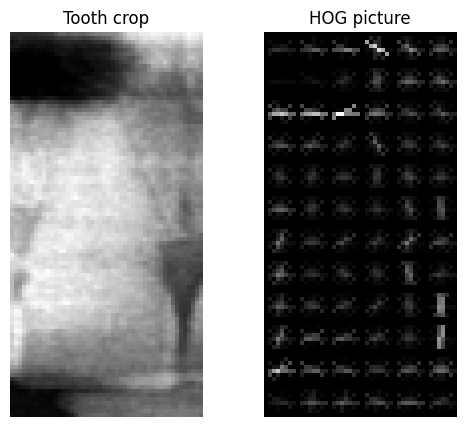

In [ ]:
import matplotlib.pyplot as plt

name = enum_df["file_name"].iloc[0]
x, y, w, h = enum_df["box"].iloc[0]
img = Image.open(enum_paths[name]).convert("L")
crop = ImageOps.autocontrast(img.crop((int(x), int(y), int(x + w), int(y + h)))).resize(TOOTH_SIZE)

features, hog_picture = get_hog(np.asarray(crop, dtype=np.float32) / 255, show=True)
print("Number of HOG features for one tooth:", len(features))

fig, axes = plt.subplots(1, 2, figsize=(6, 5))
axes[0].imshow(crop, cmap="gray");        axes[0].set_title("Tooth crop")
axes[1].imshow(hog_picture, cmap="gray"); axes[1].set_title("HOG picture")
for a in axes:
    a.axis("off")
plt.show()

# MODEL 3: Abnormality


In [12]:
with open(DIS_JSON) as f:
    data = json.load(f)

file_of  = {im["id"]: im["file_name"] for im in data["images"]}
quad_of  = {c["id"]: int(c["name"]) for c in data["categories_1"]}
tooth_of = {c["id"]: int(c["name"]) for c in data["categories_2"]}
abn_of   = {c["id"]: c["name"] for c in data["categories_3"]}
rows = []
for a in data["annotations"]:
    quadrant = quad_of[a["category_id_1"]]
    tooth = tooth_of[a["category_id_2"]]
    rows.append({"file_name": file_of[a["image_id"]],
                 "box": tuple(a["bbox"]),
                 "quadrant": quadrant,
                 "tooth_number": tooth,
                 "fdi_position": quadrant * 10 + tooth,
                 "abnormality": abn_of[a["category_id_3"]]})
dis_df = pd.DataFrame(rows)

print(len(dis_df), "abnormal teeth from", dis_df["file_name"].nunique(), "images")
print(dis_df["abnormality"].value_counts())
dis_df[["file_name", "quadrant", "tooth_number", "abnormality", "box"]].head()

3529 abnormal teeth from 678 images
abnormality
Caries               2189
Impacted              604
Deep Caries           578
Periapical Lesion     158
Name: count, dtype: int64


,file_name,quadrant,tooth_number,abnormality,box
0,train_673.png,4,8,Impacted,"(542.0, 698.0, 220.0, 271.0)"
1,train_673.png,3,8,Impacted,"(1952.0, 693.0, 177.0, 270.0)"
2,train_673.png,4,7,Caries,"(675.0, 708.0, 243.0, 300.0)"
3,train_673.png,3,3,Caries,"(1463.0, 725.0, 98.0, 425.0)"
4,train_673.png,3,4,Caries,"(1536.0, 753.0, 103.0, 381.0)"


##  Build features for Model 3


In [13]:
dis_paths = find_images(DIS_IMG_DIR)
pix3, pos3, dis_df = make_features(dis_df, dis_paths, TOOTH_SIZE)
X3 = np.hstack([pix3,
                one_hot(dis_df["quadrant"].values, 4),
                one_hot(dis_df["tooth_number"].values, 8)])
y3 = dis_df["abnormality"].to_numpy(dtype=str)

dentex_train/training_data/quadrant-enumeration-disease -> 705 images found
used 3529 of 3529 rows


In [14]:
groups3 = dis_df["file_name"].to_numpy(dtype=str)
train3, test3 = split_70_30(groups3)
print("training teeth:", len(train3), "| test teeth:", len(test3))

model3 = make_pipeline(StandardScaler(),
                       LogisticRegression(class_weight="balanced"))
grid3 = tune(model3, X3[train3], y3[train3], groups3[train3], PARAM_GRID)

model3 = grid3.best_estimator_

pred3 = model3.predict(X3[test3])
print("Test abnormality accuracy:", accuracy_score(y3[test3], pred3))

test_names = groups3[test3]
joblib.dump(model3, "model3_abnormality.pkl")

training teeth: 2502 | test teeth: 1027
    C  max_iter  mean_f1_macro      std
0.005       150       0.533612 0.013574
0.005       100       0.533612 0.013574
0.005       300       0.533612 0.013574
0.005       500       0.533612 0.013574
0.005      1000       0.533612 0.013574
0.005      2000       0.533612 0.013574
0.010       100       0.523317 0.012296
0.010       150       0.522660 0.011479
0.010       300       0.522660 0.011479
0.010       500       0.522660 0.011479
Best settings: {'C': 0.005, 'max_iter': 150}
Best CV Macro F1: 0.5336
-> best C is at the edge of its list: try smaller/larger values and re-run
Test abnormality accuracy: 0.6387536514118792


['model3_abnormality.pkl']

In [17]:
print("Test precision:", precision_score(y3[test3], pred3, average='macro'))
print("Test recall:", recall_score(y3[test3], pred3, average='macro'))
print("Test F1-score:", f1_score(y3[test3], pred3, average='macro'))

print("Confusion matrix:")
print(confusion_matrix(y3[test3], pred3))

Test precision: 0.5531083587990477
Test recall: 0.5949040791154574
Test F1-score: 0.5644376725687138
Confusion matrix:
[[396 160  25  40]
 [ 70  80   8  10]
 [ 14  14 159   1]
 [ 21   7   1  21]]
